# Looking at particles: a contact sheet, a gallery, and the triage page

Every size distribution this package writes is built from particles you can look at. This
notebook decodes the tracked demo flight and shows three ways to see what the reject stage
decided:

1. a contact sheet of single particles, in matplotlib (`arrayprobe.render`);
2. a whole flight written to folders of images (`arrayprobe gallery`);
3. the triage page in your browser (`arrayprobe triage`), where you label particles.

**What you will learn:** how to open the decoded particle file and read its units, how to
draw particles as a contact sheet, how to write a whole flight to image folders, and how to start
the triage page.

**What data:** the tracked synthetic demo flight described below; no download is needed.

Looking and labelling compute nothing: no number in any product changes. The input is
`tests/data/demo_flight_dense_raw.2DS`, a hand-built 20-second 2D-S file of 240 synthetic
particles, not cloud.

**Before this:** [04_soda2_end_to_end](04_soda2_end_to_end.ipynb) (SODA-2 end to end). **Next:** [06_read_products](06_read_products.ipynb). **Needs:** `pip install "arrayprobe[extra,zarr]"` (matplotlib, xarray).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

## 1. Decode the dense demo flight

`run_flight.py`'s stage functions on the v3.5 engine (`run_flight.use_engine_35`), into one
directory -- the layout the gallery and the triage server both read
(`<flight>.H.nc` beside `proc.<flight>.H.nc`).

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/1_getting_started/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

import shutil
import sys
import tempfile
from pathlib import Path

import numpy as np
import xarray as xr   # reads the output files; an example-only dependency, see examples/README.md

sys.path.insert(0, "scripts")
import run_flight  # noqa: E402

run_flight.log = lambda *a, **kw: None  # quiet the tool's own progress prints
tmp = tempfile.TemporaryDirectory()
decoded = Path(tmp.name) / "decoded"
decoded.mkdir()
raw = decoded / "base160101000000.2DS"
shutil.copyfile("tests/data/demo_flight_dense_raw.2DS", raw)
run_flight.use_engine_35(decoded)  # public package: v3.5 engine, stock-v3.5 profile, constant-TAS aircraft file
image = run_flight.stage2(raw, decoded)
proc = run_flight.stage3(image, decoded)
FLIGHT = "base160101000000.H"

with xr.open_dataset(proc, mask_and_scale=False, decode_times=False) as ds:
    reject = np.asarray(ds["image_auto_reject"][:]).astype(int)
codes = {chr(c): int((reject == c).sum()) for c in np.unique(reject)}
print(f"{image.name} + {proc.name}: {reject.size} particles, reject codes {codes}")
print("('0' is accepted; the letter codes are decoded in 02_read_products.ipynb)")

base160101000000.H.nc + proc.base160101000000.H.nc: 240 particles, reject codes {'0': 160, 'H': 40, 'h': 40}
('0' is accepted; the letter codes are decoded in 02_read_products.ipynb)


### The particle file, opened with xarray

`proc.<flight>.H.nc` holds one row per particle. Opening it with `xarray` shows every variable,
and each variable carries its units in a `Units` attribute.


In [2]:
import re


def without_local_paths(data):
    """A copy whose path-valued global attributes keep only the file name.

    The file records the absolute path of the input the demo run read; showing it
    would print a folder on this machine. The file on disk is unchanged."""
    shown = data.copy()
    shown.attrs = {k: re.split(r"[/\\]", v)[-1] if isinstance(v, str) and re.match(r"(~|[A-Za-z]:|/)", v) else v
                   for k, v in data.attrs.items()}
    return shown


with xr.open_dataset(proc, decode_times=False) as ds:
    products = ds.load()
for name in ["image_diam_minR", "image_area", "Time"]:
    print(f"{name}: units {products[name].attrs.get('Units')!r}")
without_local_paths(products)


image_diam_minR: units 'mm'
image_area: units 'mm^2'
Time: units 'HHMMSS'


<xarray.Dataset> Size: 46kB
Dimensions:                         (time: 240, pos_count: 2, bin_count: 128)
Dimensions without coordinates: time, pos_count, bin_count
Data variables: (12/40)
    Date                            (time) int32 960B 20160906 ... 20160906
    Time                            (time) int32 960B 60640 60640 ... 60659
    msec                            (time) int16 480B 250 250 250 ... 250 250
    Time_in_seconds                 (time) float64 2kB 20.65 20.65 ... 20.7 20.7
    SliceCount                      (time) int16 480B 14 9 16 16 ... 40 16 16 26
    DMT_DOF_SPEC_OVERLOAD           (time) float64 2kB 0.0 0.0 0.0 ... 0.0 0.0
    ...                              ...
    holroyd_habit                   (time) int16 480B 115 115 115 ... 115 115
    fine_detail_ratio               (time) float64 2kB 4.182 10.0 ... 4.449
    sphericity                      (time) float64 2kB 0.3266 0.3099 ... 0.2707
    area_hole_ratio                 (time) float64 2kB 0.0 0.0 ... 5.231 0.0
    inter_arrival                   (time) float64 2kB 0.0 ... 0.0003077
    bin_stats                       (bin_count) int32 512B 0 0 0 0 0 ... 0 0 0 0
Attributes: (12/14)
    Software:                            UIOOPS_v3.5
    Creation Time:                       2026/10/30 20:49:44
    Description:                         Contains size, morphological, and ot...
    Project:                             ORACLES
    Image Source:                        base160101000000.H.nc
    Probe Type:                          2DS
    ...                                  ...
    arrayprobe_profile:                  stock-v3.5
    arrayprobe_tas_s3_fallback_records:  0
    arrayprobe_tas_s3_fallback_seconds:  none
    arrayprobe_tas_s3_records_total:     20
    arrayprobe_tas_s3_source:            aircraft.cdf
    arrayprobe_tas_s3_uncertainty:       every image record matched an aircra...

The first five particles, with plain column names and the units in each header:


In [3]:
import pandas as pd

first = slice(0, 5)
pd.DataFrame({
    "particle": np.arange(5),
    "time (HHMMSS, UTC)": products["Time"].values[first],
    "size: smallest enclosing circle (mm)": products["image_diam_minR"].values[first].round(3),
    "area (mm^2)": products["image_area"].values[first].round(4),
    "reject code": [chr(int(c)) for c in products["image_auto_reject"].values[first]],
})


,particle,"time (HHMMSS, UTC)",size: smallest enclosing circle (mm),area (mm^2),reject code
0,0,60640,0.149,0.0154,0
1,1,60640,0.091,0.0018,h
2,2,60640,0.088,0.0068,H
3,3,60640,0.088,0.0068,H
4,4,60640,0.091,0.0018,h


## 2. Single particles and a contact sheet

`render_particle` reconstructs one particle's silhouette from the decoded record and labels it
with its reject code, habit and minimum-enclosing-circle diameter. `render_contact_sheet` lays
several out in a grid. **`crop=True` is an opt-in** (default off, so the full diode-search window
is shown); at thumbnail scale it is usually what you want, because the window can be much larger
than the particle right after a record reset.

### Plain-word panel titles

`arrayprobe.render` labels each panel with raw codes (`reject='0' habit='s' diam=0.149mm`). The
helper below rewrites that label in words, taking the reject outcome from
`arrayprobe.triage_context.reject_outcome` and the habit word from the triage page's own table
(`arrayprobe.triage_server.HABIT_WORDS`); a code with no documented meaning is shown as the code.

In [4]:
import re

from arrayprobe.triage_context import reject_outcome
from arrayprobe.triage_server import HABIT_WORDS


def plain_title(n, label):
    """Plain words for a render label "rec R #N reject='x' habit='y' diam=D.DDDmm"."""
    m = re.search(r"reject='(.*?)' habit='(.*?)' diam=(\S+)", label)
    if m is None:
        return f"Particle {n}"
    code, habit, diam = m.groups()
    outcome = reject_outcome(code)
    decided = outcome[1].split(":")[0] if outcome else f"reject code {code!r}"
    if code != "0":
        decided += f" (code {code})"
    habit_words = HABIT_WORDS.get(habit, f"habit code {habit!r}")
    size = f"{float(diam[:-2]) * 1000:.0f} \u00b5m" if diam.endswith("mm") else "size n/a"
    return f"Particle {n}: {decided},\n{habit_words}, {size}"

The renderers read the raw on-disk variables, so the cell below opens the two files with
`netCDF4` rather than `xarray`: a `netCDF4` handle reads the stored bytes unscaled, as the
renderer expects.


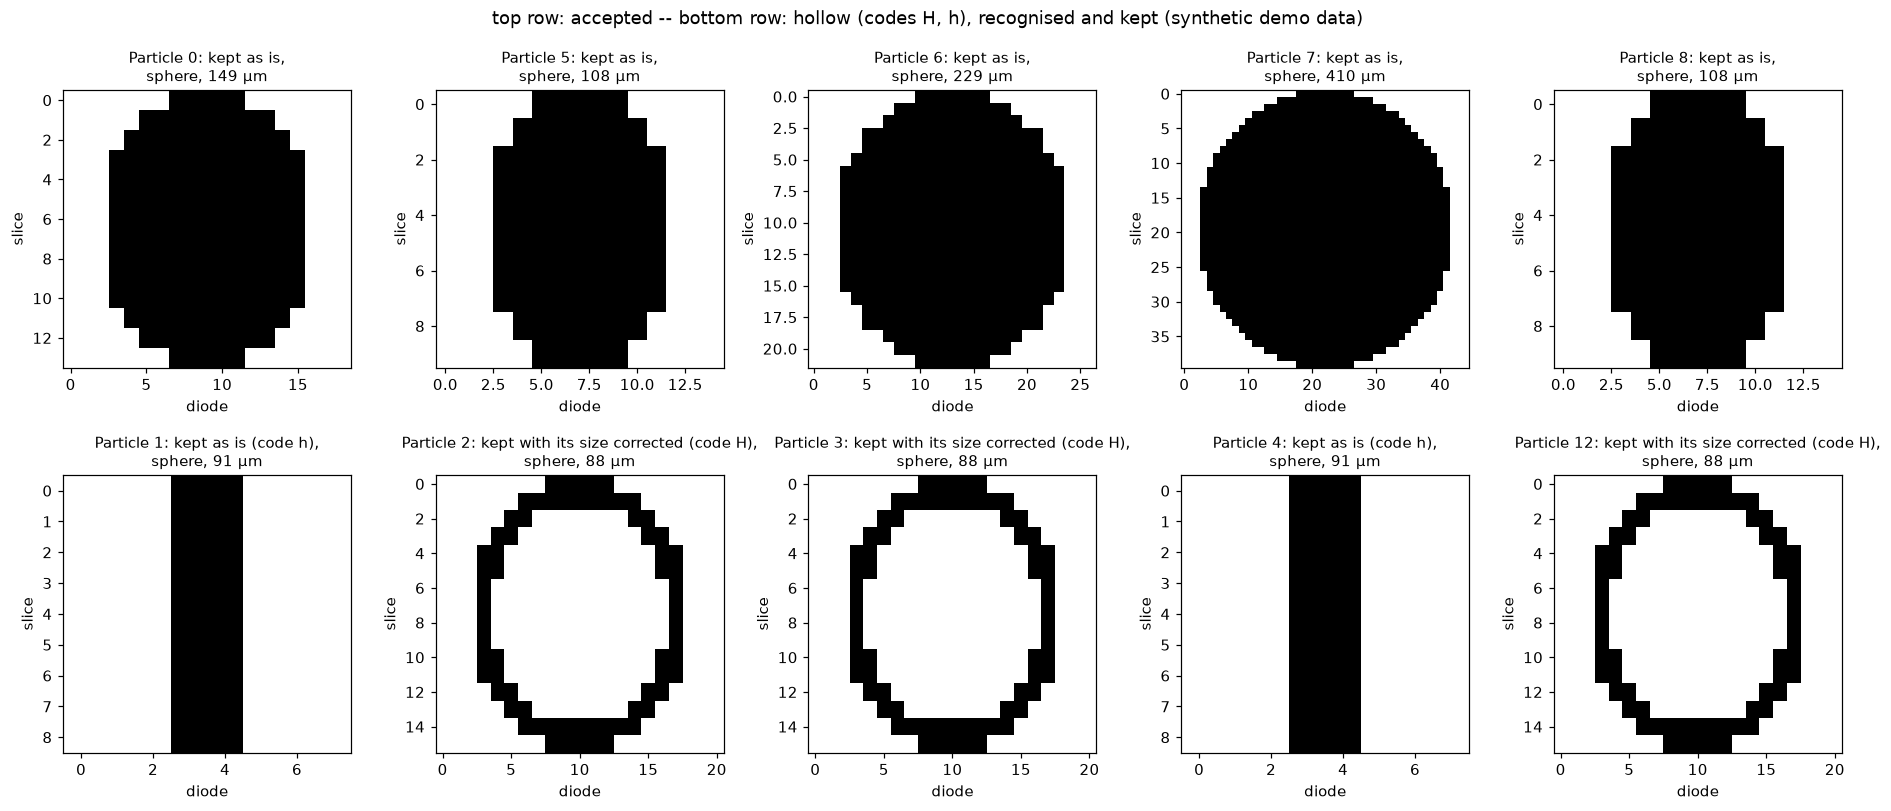

In [5]:
import matplotlib.pyplot as plt
import netCDF4   # the renderers take raw netCDF4 handles

from arrayprobe.render import render_contact_sheet
from arrayprobe_uiops.sizedist_core import GOOD_REJECT_CODES

kept = np.isin(reject, [ord(c) for c in GOOD_REJECT_CODES])  # v3.5 keeps 0, H, h, u, R
accepted = np.flatnonzero(reject == ord("0"))[:5]
rejected = np.flatnonzero(~kept)[:5]
second_row = "rejected"
if rejected.size == 0:  # stock v3.5 rejects none of the demo particles; use the hollow ones it recognises and keeps
    rejected = np.flatnonzero(kept & (reject != ord("0")))[:5]
    second_row = "hollow (codes H, h), recognised and kept"
with netCDF4.Dataset(image) as img_ds, netCDF4.Dataset(proc) as proc_ds:
    sheet = render_contact_sheet(img_ds, proc_ds, list(accepted) + list(rejected), ncols=5, crop=True)
sheet.set_size_inches(17, 7.5)
for ax, n in zip(sheet.axes, list(accepted) + list(rejected)):
    ax.set_title(plain_title(n, ax.get_title()), fontsize=10)
    ax.tick_params(labelsize=10)
    ax.xaxis.label.set_fontsize(10)
    ax.yaxis.label.set_fontsize(10)
sheet.suptitle(f"top row: accepted -- bottom row: {second_row} (synthetic demo data)", fontsize=12)
sheet.tight_layout()
plt.show()

*Figure 1. Ten particles from the synthetic demo flight, each cropped to its shadow. Top row: particles the reject stage accepted as they are. Bottom row: hollow particles, which v3.5 recognises and keeps. Each title gives the particle's index in the file, what the reject stage did, its habit and its size.*

## 3. A whole flight on disk: `arrayprobe gallery`

One directory per second, one sub-directory per class, one PNG per particle, plus index pages.
The command a user types is shown; it is run here as a subprocess exactly as typed. Options that
change what is written, all opt-in: `--classes accepted rejected unsure` (default: accepted only,
because a real flight has hundreds of thousands of particles), `--no-crop`, `--scale N`,
`--limit N`, `--no-index`.

In [6]:
import subprocess

gallery_out = Path(tmp.name) / "gallery"
cmd = [sys.executable, "-m", "arrayprobe.cli", "gallery", "--decoded-dir", str(decoded),
       "--flight", FLIGHT, "--out", str(gallery_out), "--classes", "accepted", "rejected"]
print("$ arrayprobe gallery --decoded-dir <decoded> --flight", FLIGHT,
      "--out <gallery> --classes accepted rejected")
done = subprocess.run(cmd, capture_output=True, text=True, encoding="utf-8", errors="replace")
print("exit code:", done.returncode)
assert done.returncode == 0, done.stderr  # a failed command must fail the notebook, not print
pngs = sorted(gallery_out.rglob("*.png"))
html = sorted(gallery_out.rglob("*.html"))
seconds = sorted({p.parent.parent.name for p in pngs})
print(f"{len(pngs)} particle PNGs across {len(seconds)} second directories, {len(html)} index pages")
for cls in ("accepted", "rejected"):
    print(f"  {cls:9s} {sum(1 for p in pngs if p.parent.name == cls)}")
print("first second on disk:", seconds[0], "->", sorted(p.name for p in (gallery_out / FLIGHT / seconds[0]).iterdir()))

$ arrayprobe gallery --decoded-dir <decoded> --flight base160101000000.H --out <gallery> --classes accepted rejected
exit code: 0
240 particle PNGs across 20 second directories, 21 index pages
  accepted  240
  rejected  0
first second on disk: 060640 -> ['accepted', 'index.html']


One of the images the gallery wrote, shown as it sits on disk:


base160101000000.H\060640\accepted\p0000000.png


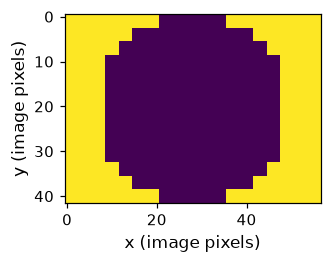

In [7]:
first_png = sorted(gallery_out.rglob("*.png"))[0]
print(first_png.relative_to(gallery_out))
fig, ax = plt.subplots(figsize=(3, 3))
ax.imshow(plt.imread(first_png))
ax.set_xlabel("x (image pixels)")
ax.set_ylabel("y (image pixels)")
plt.show()


*Figure 2. One particle image from the gallery folders, at the size the gallery writes it.*


## 4. Label particles in your browser: `arrayprobe triage`

In a terminal, from the repository root:

```bash
arrayprobe triage --decoded-dir <decoded-folder> --reviewer YOUR_NAME
```

then open <http://127.0.0.1:8765/>. The command keeps running until you press Ctrl+C.

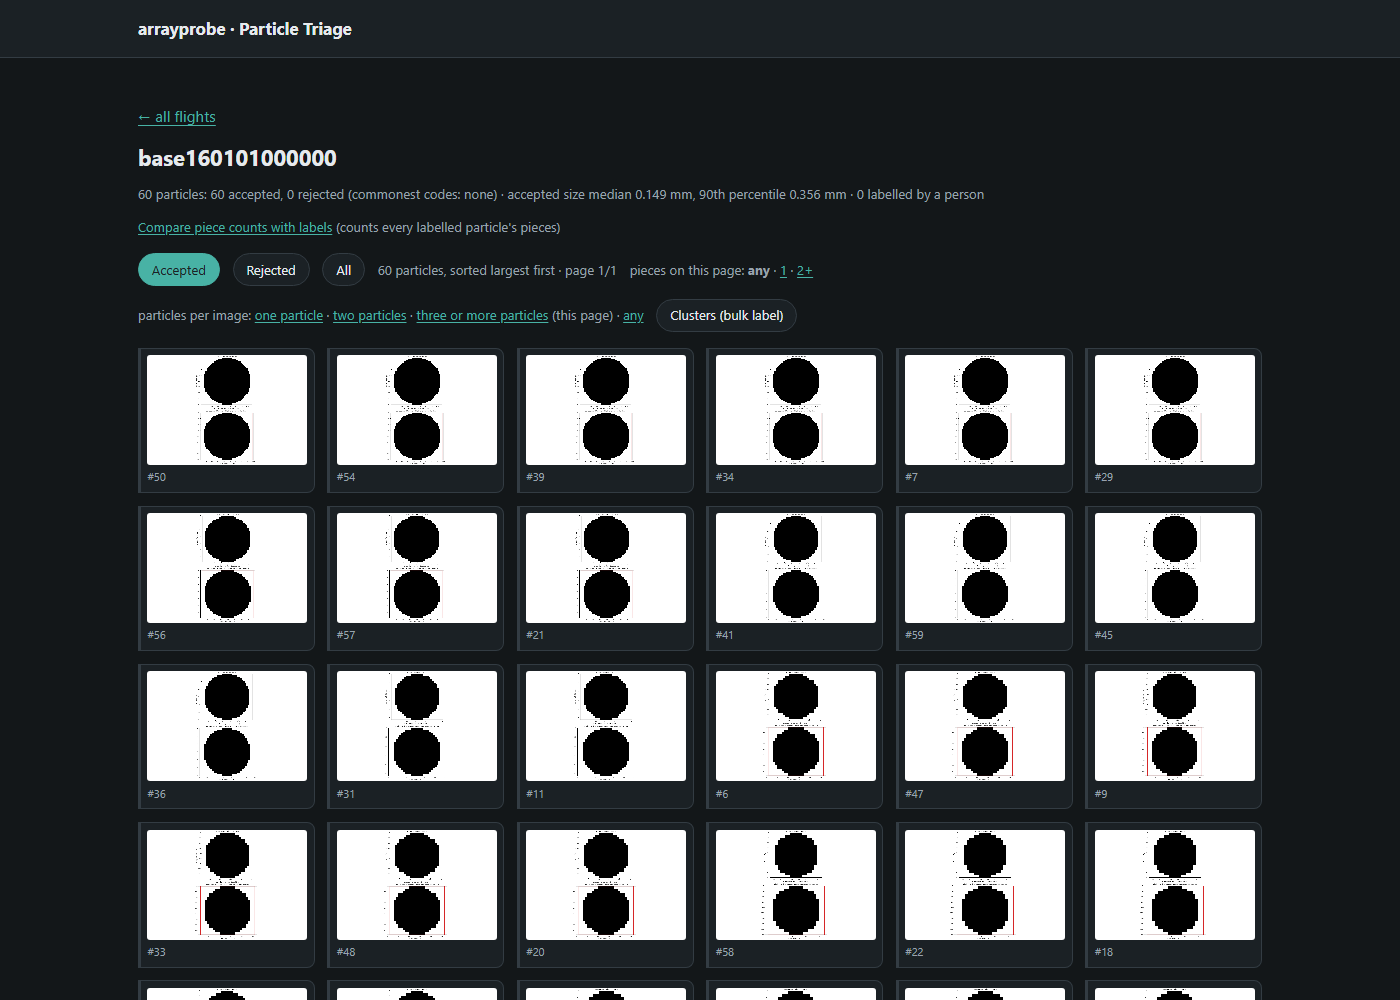

*Figure 3. A screen capture of the triage server's flight page for the synthetic demo flight decoded above: accepted particles, sorted largest first, each tile labelled with its particle index in the file. The page only displays particles; nothing on it changes a computed value.*

On the page you pick a flight, switch between accepted, rejected and all particles, and click a
particle to open its own page. There you choose `real`, `artifact`, `mixed` or `unsure`, add a
comment if you want, and save. Each label goes to `<decoded folder>/triage_verdicts/<flight>.json`,
beside the data, with your name on it.


## Where to go next

- [`06_read_products.ipynb`](06_read_products.ipynb) -- the reject and habit codes the particles above are shown against.
- [`../2_processing/10_labelling_particles.ipynb`](../2_processing/10_labelling_particles.ipynb) -- labelling in detail: the verdict store, review queues, keyboard keys, the server run from Python, and the piece-gap setting.
- `docs/03-visualisation.md` -- the gallery and triage server in full.
